# MobAI — Weekly Demand Forecasting for a Warehouse (WMS Hackathon)

Forecast next week's demand per product (SKU) from two years of order history, so the warehouse
can plan **preparation orders** (what to pick) and **storage placement** (fast movers near the exit).

**What this notebook does**
1. Reads every sheet of the data pack and keeps only what can be used without leakage.
2. Shows why **weekly** is the right forecasting level (most SKU-days have no order at all).
3. Builds lag/rolling/calendar features, each checked to be known *before* the target week.
4. Compares three forecasters with a **rolling-origin backtest over four quarters**, not a single split:
   - naive: per-SKU median of the last 26 weeks,
   - v1 (competition model): blend of LightGBM quantile models (α = 0.35–0.50) + naive median,
   - v2: **scale-normalised L1 LightGBM**, which optimises WAPE directly.

> The raw data belongs to the hackathon organiser and is **not included** in this repository.
> Place `WMS_Hackathon_DataPack_Templates_FR_FV_B7_ONLY.xlsx` next to the notebook to run it.
> Runtime ≈ 6 min on 2 CPU cores. Requires `pandas numpy matplotlib lightgbm openpyxl`.

In [1]:
import pandas as pd, numpy as np, warnings, time
import matplotlib.pyplot as plt, lightgbm as lgb
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
plt.rcParams['figure.dpi'] = 110
EXCEL = 'WMS_Hackathon_DataPack_Templates_FR_FV_B7_ONLY.xlsx'
H = 13                       # one quarter = 13 weeks

def WAPE(y, p):
    y = np.asarray(y, float); p = np.asarray(p, float); s = y.sum()
    return np.abs(y - p).sum() / s if s > 0 else np.nan
def BIAS(y, p):
    y = np.asarray(y, float); p = np.asarray(p, float); return (p.sum() - y.sum()) / y.sum()

## 1 — Data audit

In [2]:
xl = pd.ExcelFile(EXCEL)
for s in xl.sheet_names:
    df = pd.read_excel(EXCEL, sheet_name=s)
    print('  {:32s} {:>7} rows x {:>2} cols'.format(s, len(df), df.shape[1]))

d = pd.read_excel(EXCEL, sheet_name='historique_demande')
d['ts'] = pd.to_datetime(d['date']); d['day'] = d.ts.dt.normalize()
p = pd.read_excel(EXCEL, sheet_name='produits').iloc[2:].copy()
p.columns = ['id_produit','sku','nom_produit','unite_mesure','categorie','actif',
             'colisage_fardeau','colisage_palette','volume_m3','poids_kg','gerbable']
p['id_produit'] = pd.to_numeric(p.id_produit, errors='coerce')
cat = p.set_index('id_produit').categorie
print('\ndemand lines', len(d), '| SKUs', d.id_produit.nunique(), '| orders', d.ts.nunique(),
      '| window', d.day.min().date(), '->', d.day.max().date())

  LISEZ_MOI                              8 rows x  1 cols
  DICTIONNAIRE_DONNEES                  55 rows x  6 cols
  produits                            1583 rows x 11 cols


  codes_barres_produits               1583 rows x  6 cols
  entrepots                              3 rows x  5 cols
  emplacements                         840 rows x  8 cols
  utilisateurs                           9 rows x  5 cols


  transactions                        4271 rows x  7 cols


  lignes_transaction                 76890 rows x  8 cols


  historique_demande                151233 rows x  3 cols
  delais_approvisionnement               3 rows x  2 cols
  politique_reapprovisionnement          3 rows x  4 cols
  cmd_achat_ouvertes_opt                 3 rows x  5 cols
  MAPPING_EN_FR                         55 rows x  4 cols



demand lines 151233 | SKUs 1129 | orders 12959 | window 2024-01-02 -> 2026-01-08


| Sheet | Use |
|---|---|
| `historique_demande` | **target**: order lines with timestamp, SKU, quantity |
| `produits` | category and packaging attributes (`poids_kg` is all zeros, dropped) |
| `transactions`, `lignes_transaction` | deliveries/receipts — they *follow* demand (peak correlation at lag +1 day), so using them would leak the target. Not used. |
| `emplacements`, `entrepots` | warehouse layout — used by the optimisation module, not the forecaster |
| lead times, replenishment policy, open POs | 3-row placeholder templates — unusable |

## 2 — Why forecast weekly

In [3]:
op = np.sort(d.day.unique())
dd = d.groupby('day').quantite_demande.sum()
prof = dd.groupby(dd.index.dayofweek).agg(['mean', 'size'])
prof.index = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
print('Daily volume by weekday (Friday is the weekly closing day):'); print(prof.round(0).to_string())

dense = d[d.id_produit.isin(d.groupby('id_produit').day.nunique().loc[lambda s: s >= 150].index)]
piv = dense.groupby(['id_produit','day']).quantite_demande.sum().unstack(fill_value=0).reindex(columns=op, fill_value=0)
print('\nDaily zero rate (frequent SKUs only): {:.0%}'.format((piv.values == 0).mean()))
rs = [np.corrcoef(x[1:], x[:-1])[0,1] for x in piv.values.astype(float) if x.std() > 0]
print('Daily lag-1 autocorrelation: {:+.3f}  -> almost no day-to-day signal'.format(np.mean(rs)))

Daily volume by weekday (Friday is the weekly closing day):
         mean  size
Mon   98124.0   101
Tue   90556.0   102
Wed   76857.0   101
Thu   65047.0    98
Fri     224.0     3
Sat   48554.0    95
Sun  119322.0    98

Daily zero rate (frequent SKUs only): 47%
Daily lag-1 autocorrelation: +0.027  -> almost no day-to-day signal


## 3 — Weekly panel (active SKUs chosen *without* looking at the test period)

A SKU is "active" if it was ordered on at least 18 of the 180 operational days **before** the final
test quarter. (Choosing SKUs with data from the test quarter would quietly leak information about which
products will sell.)

active SKUs: 323 of 1129 (95.7% of total volume) | weeks: 104 | weekly zero rate 25%


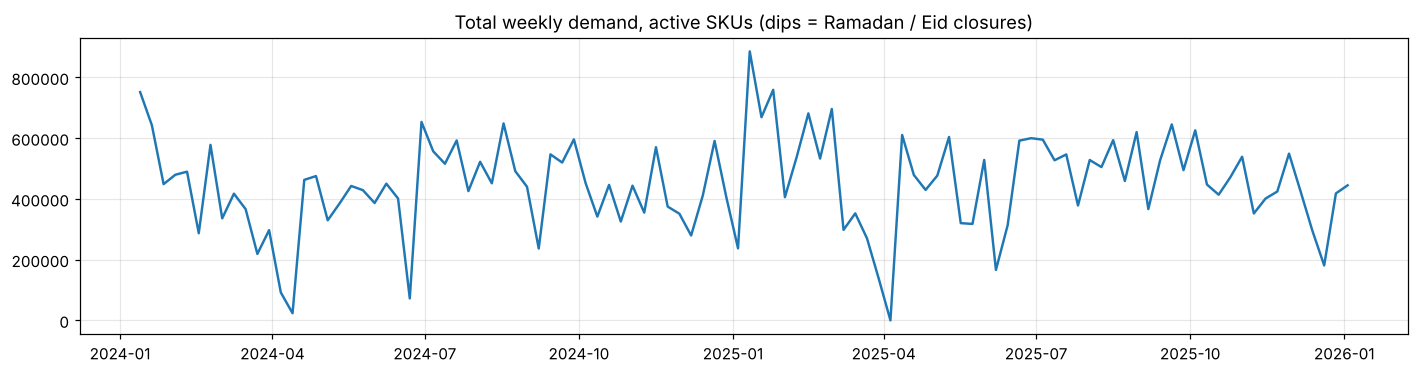

In [4]:
wall = d.groupby(pd.Grouper(key='day', freq='W-SAT')).quantite_demande.sum()
weeks_full = pd.date_range(wall.index.min(), wall.index.max(), freq='W-SAT')[1:-1]   # drop partial weeks
hold_start = weeks_full[-H] - pd.Timedelta(days=6)
window = op[op < np.datetime64(hold_start)][-180:]
g180 = d[d.day.isin(window)].groupby('id_produit').agg(nd=('day', 'nunique'))
ACTIVE = g180[g180.nd >= 18].index
sub = d[d.id_produit.isin(ACTIVE)]
wk = (sub.groupby(['id_produit', pd.Grouper(key='day', freq='W-SAT')])
         .quantite_demande.sum().unstack(fill_value=0))
wk = wk.reindex(columns=pd.date_range(wk.columns.min(), wk.columns.max(), freq='W-SAT'), fill_value=0).iloc[:, 1:-1]
V = wk.values.astype(float); nS, nW = V.shape; weeks = wk.columns
print('active SKUs: {} of {} ({:.1%} of total volume) | weeks: {} | weekly zero rate {:.0%}'.format(
      nS, d.id_produit.nunique(), sub.quantite_demande.sum() / d.quantite_demande.sum(), nW, (V == 0).mean()))

fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(weeks, V.sum(0), lw=1.6)
ax.set_title('Total weekly demand, active SKUs (dips = Ramadan / Eid closures)'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 4 — Features (all computable before the target week)

For target week *j* every history feature uses columns `< j` only:
lags 1–8 and 52, rolling mean/median/std/max/non-zero-rate over 4–52 weeks, weeks since last order,
category-level and warehouse-level history, packaging attributes, and the calendar of week *j*
(week of year, month, share of Ramadan/Eid days, planned working days).

**v2 adds scale-free copies** of every history feature, divided by the SKU's recent level
`s = mean of the last 13 weeks + 1`. A SKU selling 10 units/week and one selling 10 000 then look alike
to the trees, so patterns are shared across products.

In [5]:
RAMADAN = [('2024-03-11','2024-04-09'), ('2025-03-01','2025-03-30'), ('2026-02-18','2026-03-19')]
EID = [('2024-04-10','2024-04-12'), ('2024-06-16','2024-06-19'),
       ('2025-03-30','2025-04-01'), ('2025-06-06','2025-06-09'), ('2026-03-20','2026-03-22')]
def inr(t, rs): return any(pd.Timestamp(a) <= t <= pd.Timestamp(b) for a, b in rs)
opdays = set(pd.DatetimeIndex(op))
CAL = pd.DataFrame(index=weeks)
CAL['woy'] = weeks.isocalendar().week.values.astype(int); CAL['month'] = weeks.month
CAL['ramadan_frac'] = [np.mean([inr(w - pd.Timedelta(days=k), RAMADAN) for k in range(7)]) for w in weeks]
CAL['eid_frac'] = [np.mean([inr(w - pd.Timedelta(days=k), EID) for k in range(7)]) for w in weeks]
CAL['open_days'] = [sum((w - pd.Timedelta(days=k)) in opdays for k in range(7)) for w in weeks]
CAL['t'] = np.arange(len(weeks))

catv = pd.Series(wk.index).map(cat).values
CW = pd.DataFrame(V, index=catv).groupby(level=0).sum()
CATM = np.vstack([CW.loc[c].values for c in catv]); TOT = V.sum(0)
p2 = p.set_index('id_produit')
attr = {k: pd.Series(wk.index).map(pd.to_numeric(p2[c], errors='coerce')).values
        for k, c in [('fardeau','colisage_fardeau'), ('palette','colisage_palette'), ('vol_m3','volume_m3')]}
catcode = pd.Series(catv).astype('category').cat.codes.values

rows = []
for j in range(8, nW):
    b = pd.DataFrame({'si': np.arange(nS), 'wi': j, 'y': V[:, j]})
    for L in range(1, 9): b[f'lag{L}'] = V[:, j-L]
    for w in [4, 8, 13, 26, 52]:
        if j - w >= 0:
            seg = V[:, j-w:j]
            b[f'rm{w}'] = seg.mean(1); b[f'rmed{w}'] = np.median(seg, 1)
            b[f'rstd{w}'] = seg.std(1); b[f'rmax{w}'] = seg.max(1); b[f'rnz{w}'] = (seg > 0).mean(1)
        else:
            for pr in ['rm','rmed','rstd','rmax','rnz']: b[f'{pr}{w}'] = np.nan
    b['trend'] = b['rm4'] - b['rm13']; b['cv13'] = b['rstd13'] / (b['rm13'] + 1)
    past = V[:, :j] > 0
    b['wsl'] = np.where(past.any(1), j - (j - 1 - np.argmax(past[:, ::-1], axis=1)), 99)
    b['lag52'] = V[:, j-52] if j >= 52 else np.nan
    for w in [4, 13]: b[f'cat_rm{w}'] = CATM[:, max(0, j-w):j].mean(1)
    b['cat_lag1'] = CATM[:, j-1]; b['tot_lag1'] = TOT[j-1]; b['tot_rm4'] = TOT[max(0, j-4):j].mean()
    for k, v in attr.items(): b[k] = v
    b['cat'] = catcode
    for c in CAL.columns: b[c] = CAL.iloc[j][c]
    rows.append(b)
LONG = pd.concat(rows, ignore_index=True)

V1_FEAT = [c for c in LONG.columns if c not in ['si','wi','y','lag52','tot_lag1','tot_rm4','cat']]
BASE_FEAT = [c for c in LONG.columns if c not in ['si','wi','y']]
SCALE_COLS = [c for c in LONG.columns if c.startswith(('lag','rm','rmed','rstd','rmax')) or c == 'trend']

def scaled_frame(level):
    s = np.maximum(np.nan_to_num(np.asarray(level, float), nan=0), 0) + 1.0
    X = LONG.copy()
    for c in SCALE_COLS: X[c + '_s'] = LONG[c] / s
    X['scale'] = s
    return X
LS13 = scaled_frame(LONG.rm13.fillna(LONG.rm8))
LS26 = scaled_frame(LONG.rm26.fillna(LONG.rm13).fillna(LONG.rm8))
V2_FEAT = BASE_FEAT + [c + '_s' for c in SCALE_COLS] + ['scale']

# leak audit: no feature may be (almost) a copy of the target
corr = LS13[V2_FEAT + ['y']].corr()['y'].drop('y').abs().sort_values(ascending=False)
print('panel', LONG.shape, '| v1 features', len(V1_FEAT), '| v2 features', len(V2_FEAT))
print('max |corr(feature, target)| = {:.3f} ({}) — a leak would show > 0.95'.format(corr.iloc[0], corr.index[0]))

panel (31008, 55) | v1 features 48 | v2 features 83
max |corr(feature, target)| = 0.865 (rm26) — a leak would show > 0.95


## 5 — Models

**v1 (competition model).** LightGBM quantile regression at α = 0.35, 0.40, 0.45, 0.50 (3 seeds each),
averaged, then blended 80/20 with the naive median.

**v2 (scale-normalised L1).** WAPE is an absolute-error metric, so the loss should be absolute error on the
original scale. Training L1 on `y / s` with sample weight `s` gives exactly that, because
`s · |y/s − f| = |y − s·f|`. The model predicts a *multiplier of the SKU's recent level*, which is easier to
learn across products of very different size. Two variants (level = 13-week or 26-week mean) are averaged.

In [6]:
def lgbm(obj, X_tr, y_tr, X_te, w=None, alpha=0.5, leaves=31, lr=0.05, n=400, mcs=30, sub=True, seeds=(0,1,2)):
    acc = np.zeros(len(X_te))
    for s in seeds:
        kw = dict(n_estimators=n, learning_rate=lr, num_leaves=leaves, min_child_samples=mcs,
                  colsample_bytree=0.8, verbose=-1, random_state=s)
        if sub: kw.update(subsample=0.8, subsample_freq=1)
        m = lgb.LGBMRegressor(objective=obj, alpha=alpha, **kw)
        m.fit(X_tr, y_tr, sample_weight=w); acc += m.predict(X_te)
    return np.clip(acc / len(seeds), 0, None)

def naive(te, start):
    return te.si.map(pd.Series(np.median(V[:, max(0, start-26):start], axis=1))).values

def v1(start, end):
    tr, te = LONG[LONG.wi < start], LONG[(LONG.wi >= start) & (LONG.wi < end)]
    q = np.mean([lgbm('quantile', tr[V1_FEAT], tr.y, te[V1_FEAT], alpha=a, lr=0.08, n=300, mcs=20, sub=False)
                 for a in [0.35, 0.40, 0.45, 0.50]], axis=0)
    return 0.8 * q + 0.2 * naive(te, start)

def v2(start, end):
    out = []
    for X, leaves in [(LS13, 31), (LS26, 63)]:
        tr, te = X[X.wi < start], X[(X.wi >= start) & (X.wi < end)]
        out.append(lgbm('quantile', tr[V2_FEAT], tr.y / tr.scale, te[V2_FEAT], w=tr.scale,
                        alpha=0.5, leaves=leaves) * te.scale.values)
    return np.mean(out, axis=0)

## 6 — Rolling-origin backtest over four quarters

Each quarter is forecast by a model trained **only on weeks before it**, one week ahead
(the operational use case: on Saturday, forecast the coming week). Model choices were made on
quarters 1–3; quarter 4 (Oct 2025 → Jan 2026) was run once at the end.
Four quarters give a far steadier estimate than one 13-week split.

In [7]:
wmonth = pd.Series(weeks).dt.to_period('M').values
cntm = pd.Series(1, index=weeks).groupby(wmonth).sum()
full_months = [m for m in cntm.index if cntm[m] >= 4]
def monthly_wape(te, pred):
    t = te[['si','wi','y']].copy(); t['p'] = pred; t['m'] = pd.Series(wmonth)[t.wi.values].values
    a = t[t.m.isin(full_months)].groupby(['si','m'])[['y','p']].sum()
    return WAPE(a.y, a.p)

QUARTERS = [(nW - 4*H, nW - 3*H), (nW - 3*H, nW - 2*H), (nW - 2*H, nW - H), (nW - H, nW)]
res, store = [], {}
for qi, (a, b) in enumerate(QUARTERS, 1):
    t0 = time.time()
    te = LONG[(LONG.wi >= a) & (LONG.wi < b)]
    preds = {'naive median-26': naive(te, a), 'v1 quantile blend': v1(a, b), 'v2 scale-norm L1': v2(a, b)}
    store[qi] = (te, preds)
    label = '{} → {}'.format((weeks[a] - pd.Timedelta(days=6)).date(), weeks[b-1].date())
    for m, pr in preds.items():
        res.append(dict(quarter=f'Q{qi} {label}', model=m, weekly_WAPE=WAPE(te.y, pr),
                        BIAS=BIAS(te.y, pr), monthly_WAPE=monthly_wape(te, pr)))
    print(f'quarter {qi} done ({time.time()-t0:.0f}s)')
R = pd.DataFrame(res)
print(R.pivot(index='quarter', columns='model', values='weekly_WAPE').round(3).to_string())

quarter 1 done (27s)


quarter 2 done (36s)


quarter 3 done (42s)


quarter 4 done (46s)
model                       naive median-26  v1 quantile blend  v2 scale-norm L1
quarter                                                                         
Q1 2025-01-05 → 2025-04-05            0.589              0.564             0.548
Q2 2025-04-06 → 2025-07-05            0.482              0.528             0.428
Q3 2025-07-06 → 2025-10-04            0.431              0.426             0.434
Q4 2025-10-05 → 2026-01-03            0.512              0.486             0.506


Average over the four quarters
                   weekly_WAPE  monthly_WAPE   BIAS  quarters won (weekly)
model                                                                     
naive median-26          0.504         0.360 -0.144                    0.0
v1 quantile blend        0.501         0.363 -0.168                    2.0
v2 scale-norm L1         0.479         0.316 -0.082                    2.0


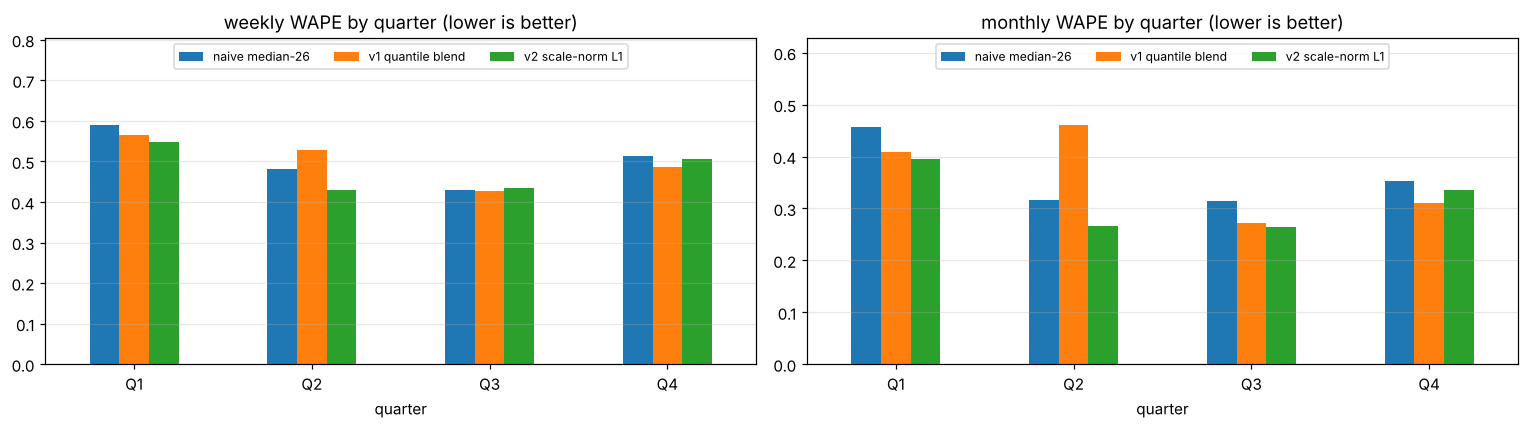

In [8]:
summary = R.groupby('model')[['weekly_WAPE', 'monthly_WAPE', 'BIAS']].mean().round(3)
summary['quarters won (weekly)'] = R.loc[R.groupby('quarter').weekly_WAPE.idxmin()].model.value_counts()
print('Average over the four quarters'); print(summary.fillna(0).to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for k, met in enumerate(['weekly_WAPE', 'monthly_WAPE']):
    R.pivot(index='quarter', columns='model', values=met).plot(kind='bar', ax=ax[k], rot=0)
    ax[k].set_ylim(0, ax[k].get_ylim()[1] * 1.3); ax[k].legend(ncol=3, loc='upper center', fontsize=8)
    ax[k].set_title(met.replace('_', ' ') + ' by quarter (lower is better)'); ax[k].grid(alpha=.3, axis='y')
    ax[k].set_xticklabels([f'Q{i}' for i in range(1, 5)])
plt.tight_layout(); plt.show()

## 7 — Actual vs forecast (last quarter)

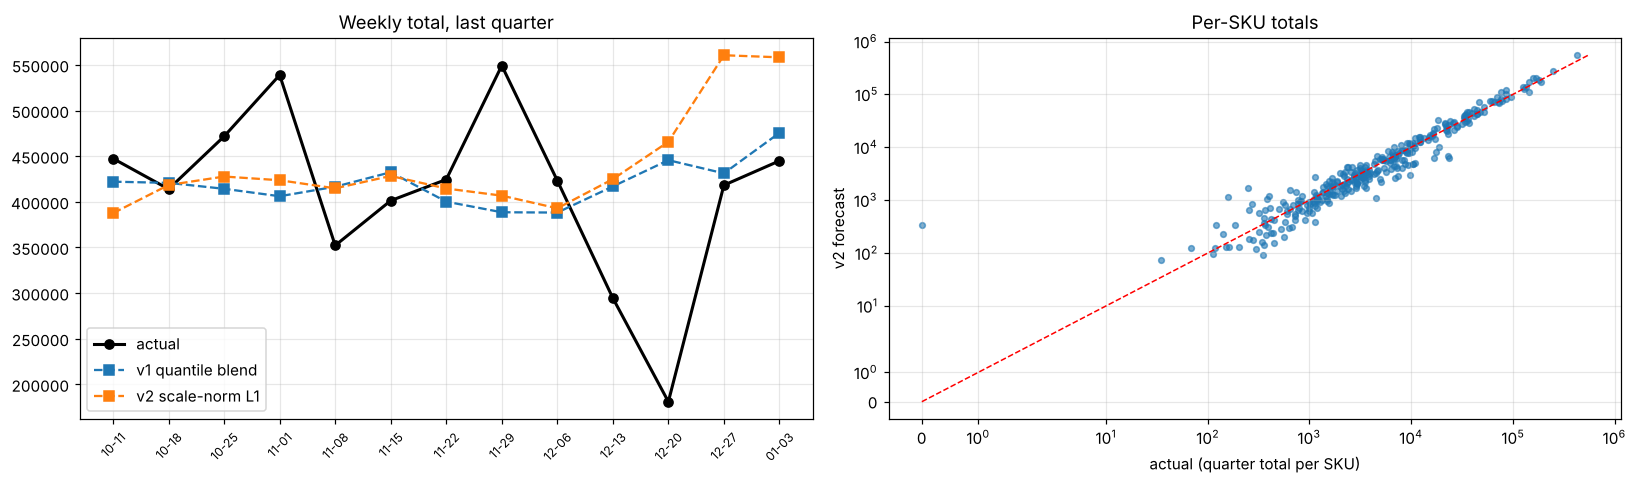

Weekly WAPE by scope, all four quarters pooled (v2):
  top  50 SKUs (73.8% of volume): WAPE 0.412
  top 100 SKUs (88.2% of volume): WAPE 0.439
  top 200 SKUs (97.3% of volume): WAPE 0.464
  top 323 SKUs (100.0% of volume): WAPE 0.477


In [9]:
te, preds = store[4]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
t = te.assign(**{k: v for k, v in preds.items()}).groupby('wi')[['y'] + list(preds)].sum()
ax[0].plot(range(len(t)), t.y, 'o-', lw=2, color='k', label='actual')
for m in ['v1 quantile blend', 'v2 scale-norm L1']: ax[0].plot(range(len(t)), t[m], 's--', label=m)
ax[0].set_xticks(range(len(t))); ax[0].set_xticklabels([weeks[i].strftime('%m-%d') for i in t.index], rotation=45, fontsize=8)
ax[0].set_title('Weekly total, last quarter'); ax[0].legend(); ax[0].grid(alpha=.3)
s = te.assign(p=preds['v2 scale-norm L1']).groupby('si')[['y', 'p']].sum()
ax[1].scatter(s.y, s.p, s=14, alpha=.6); mx = max(s.y.max(), s.p.max()); ax[1].plot([0, mx], [0, mx], 'r--', lw=1)
ax[1].set_xscale('symlog'); ax[1].set_yscale('symlog'); ax[1].grid(alpha=.3)
ax[1].set_xlabel('actual (quarter total per SKU)'); ax[1].set_ylabel('v2 forecast'); ax[1].set_title('Per-SKU totals')
plt.tight_layout(); plt.show()

vol = V.sum(1); order = np.argsort(-vol)
print('Weekly WAPE by scope, all four quarters pooled (v2):')
allte = pd.concat([store[q][0] for q in store]); allp = np.concatenate([store[q][1]['v2 scale-norm L1'] for q in store])
for N in [50, 100, 200, nS]:
    msk = allte.si.isin(set(order[:N])).values
    print('  top {:3d} SKUs ({:5.1%} of volume): WAPE {:.3f}'.format(N, vol[order[:N]].sum() / vol.sum(), WAPE(allte.y[msk], allp[msk])))

## 8 — Conclusions

- **Weekly is the right level.** Daily demand per SKU is mostly zeros with almost no autocorrelation;
  weekly totals keep enough signal to beat the naive median. Monthly WAPE is lower because timing
  errors inside a month cancel; it answers a coarser planning question with the same model.
- **v2 is the better general model.** Optimising WAPE directly on scale-free features gives the lowest
  four-quarter average for weekly WAPE (0.48 vs 0.50), monthly WAPE (0.32 vs 0.36) and bias. It wins
  Q1 and Q2 clearly and is slightly behind v1 in Q3 and Q4, so the figure to quote is the
  **four-quarter average**, not the best single split.
- **v1's edge over the naive median was small** once evaluated honestly (0.501 vs 0.504 on average).
- **Bias moves with the market.** In the 2025 growth quarters every model under-forecasts; in the
  last quarter they over-forecast. A median-type forecaster is WAPE-optimal but tends to sit below
  the mean; a safety-stock rule on top of the forecast is the right place to manage stock-out risk.
- **Evaluation fixes vs the competition notebook.** The competition version selected α on a fold
  that was also the reported holdout, and chose active SKUs using the holdout period. Both are
  fixed here; the honest four-quarter number is the one to quote.
- **Error is concentrated in the long tail.** The top 100 SKUs (~88 % of volume) are forecast much
  better than the full set; spiky and discontinued items drive most of the remaining error.